<a href="https://colab.research.google.com/github/ritikkumar90/TSP/blob/main/OMAsignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
cd "/content/drive/MyDrive/Colab Notebooks/TSP"

/content/drive/MyDrive/Colab Notebooks/TSP


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
BASE = "/content/drive/MyDrive/Colab Notebooks/TSP"
import os
os.chdir(BASE)
print(os.getcwd())

/content/drive/MyDrive/Colab Notebooks/TSP


In [29]:
# from pathlib import Path

# def print_tree(directory=".", prefix=""):
#     """Recursively prints a directory tree."""
#     path = Path(directory)

#     # Ignore hidden files/folders (optional)
#     entries = [e for e in path.iterdir() if not e.name.startswith('.')]
#     # Sort: folders first, then files alphabetically
#     entries = sorted(entries, key=lambda x: (x.is_file(), x.name.lower()))

#     entries_count = len(entries)

#     for i, entry in enumerate(entries):
#         is_last = (i == entries_count - 1)
#         connector = "└── " if is_last else "├── "

#         print(f"{prefix}{connector}{entry.name}")

#         if entry.is_dir():
#             extension = "    " if is_last else "│   "
#             print_tree(entry, prefix=prefix + extension)

# if __name__ == "__main__":
#     print(Path(".").absolute().name)
#     print_tree(".")

In [ ]:
!git clone https://github.com/xybFight/NAR4TSP.git
!git clone https://github.com/xbresson/TSP_Transformer.git
!git clone https://github.com/wouterkool/attention-learn-to-route.git
!git clone https://github.com/chaitjo/graph-convnet-tsp.git
!git clone https://github.com/yhnju/tspFormer.git

Cloning into 'NAR4TSP'...
remote: Enumerating objects: 48, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 48 (delta 20), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (48/48), 30.48 MiB | 11.74 MiB/s, done.
Resolving deltas: 100% (20/20), done.
Cloning into 'TSP_Transformer'...
remote: Enumerating objects: 91, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 91 (delta 25), reused 61 (delta 24), pack-reused 27 (from 1)
Receiving objects: 100% (91/91), 65.83 MiB | 13.34 MiB/s, done.
Resolving deltas: 100% (26/26), done.
Updating files: 100% (43/43), done.
Cloning into 'attention-learn-to-route'...
remote: Enumerating objects: 314, done.
remote: Total 314 (delta 0), reused 0 (delta 0), pack-reused 314 (from 1)
Receiving objects: 100% (314/314), 76.27 MiB | 13.38 MiB/s, done.
Resolving deltas: 100% (107/107), done.
Updating files: 100% (

In [5]:
gitignore_content = """# Cloned repositories
NAR4TSP/
TSP_Transformer/
attention-learn-to-route/
graph-convnet-tsp/
tspFormer/

# Python/Colab temporary files
__pycache__/
*.py[cod]
.ipynb_checkpoints/
"""

with open('.gitignore', 'w') as f:
    f.write(gitignore_content)

print(".gitignore file created successfully!")


.gitignore file created successfully!


In [ ]:
!git clone https://github.com/xybFight/NAR4TSP.git
!git clone https://github.com/xbresson/TSP_Transformer.git
!git clone https://github.com/wouterkool/attention-learn-to-route.git
!git clone https://github.com/chaitjo/graph-convnet-tsp.git
!git clone https://github.com/yhnju/tspFormer.git

Cloning into 'NAR4TSP'...
remote: Enumerating objects: 48, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 48 (delta 20), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (48/48), 30.48 MiB | 11.58 MiB/s, done.
Resolving deltas: 100% (20/20), done.
Updating files: 100% (10/10), done.
Cloning into 'TSP_Transformer'...
remote: Enumerating objects: 91, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 91 (delta 25), reused 61 (delta 24), pack-reused 27 (from 1)
Receiving objects: 100% (91/91), 65.83 MiB | 11.09 MiB/s, done.
Resolving deltas: 100% (26/26), done.
Updating files: 100% (43/43), done.
Cloning into 'attention-learn-to-route'...
remote: Enumerating objects: 314, done.
remote: Total 314 (delta 0), reused 0 (delta 0), pack-reused 314 (from 1)
Receiving objects: 100% (314/314), 76.27 MiB | 10.16 MiB/s, done.
Resolving deltas: 100% (10

In [ ]:
import os, sys, json, ast, time, gc, statistics, torch, pandas as pd
from torch import nn

os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"
BASE = "/content/drive/MyDrive/Colab Notebooks/TSP"
CSV  = f"{BASE}/results.csv"
dev  = torch.device("cuda"); print(torch.cuda.get_device_name(0))

SIZES = [50, 100]
M     = 500                                  # same first-500 instances for every model and mode
BATCH = {50: 500, 100: 100}                  # chunk size for the batched mode
BRE_CKPT = {50: "checkpoint_21-03-01--17-25-00-n50-gpu0.pkl",
            100: "checkpoint_21-03-01--17-09-47-n100-gpu0,1.pkl"}
NAR_K = {50: 10, 100: 20}                    # CHECK against val.py (printed below)

def sync(): torch.cuda.synchronize()

# ---- NAR4TSP code (once) ----
os.chdir(f"{BASE}/NAR4TSP")
src = open("val.py").read()
print("--- val.py lines using the neighbour count (verify NAR_K) ---")
for l in src.split("\n"):
    if "Generate_Two_Matrix" in l: print(l.strip())
nar = {}; exec(compile(src.split("class DotDict")[0], "val.py", "exec"), nar)

# ---- Bresson code: per-size notebook ----
def bresson_ns(N):
    nbk = json.load(open(f"{BASE}/TSP_Transformer/test_tsp_transformer_beamsearch_TSP{N}.ipynb"))
    code = "\n\n".join("".join(c["source"]) for c in nbk["cells"] if c["cell_type"] == "code")
    code = "\n".join(l for l in code.split("\n") if not l.lstrip().startswith(("%", "!")))
    prefix = code.split("model_baseline = TSP_net(")[0]
    ns = {"__name__": "bresson"}
    for node in ast.parse(prefix).body:
        seg = ast.get_source_segment(prefix, node) or ""
        if not isinstance(node, (ast.FunctionDef, ast.ClassDef)) and \
           any(k in seg for k in ("chdir", "drive.mount", "concorde", "google.colab")):
            continue
        try: exec(compile(ast.Module(body=[node], type_ignores=[]), "bresson", "exec"), ns)
        except Exception as e: print("skipped:", seg.split("\n")[0][:70], "->", type(e).__name__)
    return ns

KOOL = f"{BASE}/attention-learn-to-route"; sys.path.insert(0, KOOL)

# ---- loaders: each returns (solve_fn, model) ----
def load_nar(N):
    os.chdir(f"{BASE}/NAR4TSP")
    m = nn.DataParallel(nar["PointGnnModel"](128, 8, 6, 2))
    m.load_state_dict(torch.load(f"{BASE}/NAR4TSP/checkpoint/checkpoint-n{N}.pkl",
                                 map_location=dev, weights_only=False)["parameter"])
    core = m.to(dev).eval().module
    def solve(xb):
        with torch.no_grad():
            dis, mask = nar["Generate_Two_Matrix"](xb, NAR_K[N])
            score, edges = core(mask, dis, xb)
            return nar["greedy_search"](score, edges)
    return solve, core

def load_bre(N):
    ns = bresson_ns(N); a = ns["args"]
    m = ns["TSP_net"](a.dim_input_nodes, a.dim_emb, a.dim_ff, a.nb_layers_encoder,
                      a.nb_layers_decoder, a.nb_heads, a.max_len_PE)
    ck = torch.load(f"{BASE}/TSP_Transformer/checkpoint/{BRE_CKPT[N]}", map_location=dev, weights_only=False)
    m.load_state_dict({k.replace("module.", "", 1): v for k, v in ck["model_baseline"].items()})
    m = m.to(dev).eval()
    if torch.is_tensor(getattr(m, "PE", None)): m.PE = m.PE.to(dev)
    def solve(xb):
        with torch.no_grad(): out = m(xb, 1, True, False)
        for o in (out if isinstance(out, (tuple, list)) else (out,)):
            if torch.is_tensor(o) and o.dtype == torch.long and tuple(o.shape) == (len(xb), N): return o
        raise RuntimeError("no tour tensor in Bresson output")
    return solve, m

def load_kool(N):
    os.chdir(KOOL)
    from utils import load_model
    m, _ = load_model(f"{KOOL}/pretrained/tsp_{N}")
    m = m.to(dev).eval(); m.set_decode_type("greedy")
    def solve(xb):
        with torch.no_grad(): _, _, pi = m(xb, return_pi=True)
        return pi
    return solve, m

LOADERS = {"NAR4TSP": load_nar, "Bresson": load_bre, "Kool": load_kool}

# ---- measurement ----
def tour_len(x, t):
    p = x.gather(1, t.unsqueeze(-1).expand(-1, -1, 2))
    return (p - p.roll(-1, dims=1)).norm(dim=2).sum(1)
def valid(t, N): return bool((t.sort(1).values == torch.arange(N, device=dev)).all())

def solve_all(solve, X, bs):
    return torch.cat([solve(X[i:i+bs]) for i in range(0, len(X), bs)])

def bench(name, N, X, OPT):
    solve, model = LOADERS[name](N)
    base = {"model": name, "n": N, "params": sum(p.numel() for p in model.parameters())}
    rows = []
    # mode 1: one instance at a time
    try:
        for _ in range(5): solve(X[:1])
        ts, tours = [], []
        for i in range(M):
            sync(); t0 = time.time(); t = solve(X[i:i+1]); sync()
            ts.append(time.time() - t0); tours.append(t)
        T = torch.cat(tours); L = tour_len(X, T).mean().item()
        rows.append({**base, "mode": "bs1", "ms_per_inst": statistics.median(ts) * 1000,
                     "gap_pct": (L / OPT - 1) * 100, "valid": valid(T, N), "peak_gb": None})
    except Exception as e: print(name, N, "bs1 failed:", type(e).__name__, str(e)[:150])
    # mode 2: batched
    try:
        bs = BATCH[N]; solve_all(solve, X, bs)                    # warm-up
        torch.cuda.reset_peak_memory_stats(); runs = []
        for _ in range(3):
            sync(); t0 = time.time(); T = solve_all(solve, X, bs); sync(); runs.append(time.time() - t0)
        L = tour_len(X, T).mean().item()
        rows.append({**base, "mode": f"batch{bs}", "ms_per_inst": statistics.median(runs) / M * 1000,
                     "gap_pct": (L / OPT - 1) * 100, "valid": valid(T, N),
                     "peak_gb": torch.cuda.max_memory_allocated() / 1e9})
    except Exception as e: print(name, N, "batched failed:", type(e).__name__, str(e)[:150])
    del solve, model; gc.collect(); torch.cuda.empty_cache()
    return rows

all_rows = []
for N in SIZES:
    X = torch.load(f"{BASE}/TSP_Transformer/data/10k_TSP{N}.pt", map_location=dev, weights_only=False)[:M]
    Xn = torch.load(f"{BASE}/NAR4TSP/data/10k_TSP{N}.pt", map_location=dev, weights_only=False)[:M]
    print(f"n={N}: the two data copies are identical:", torch.equal(X, Xn))
    OPT = torch.load(f"{BASE}/TSP_Transformer/data/10k_TSP{N}_len.pt", map_location="cpu",
                     weights_only=False)[:M].float().mean().item()
    for name in LOADERS:
        all_rows += bench(name, N, X, OPT)
        pd.DataFrame(all_rows).to_csv(CSV, index=False)           # saved after every model
df = pd.DataFrame(all_rows); print(df.round(3).to_string(index=False))

Tesla T4
--- val.py lines using the neighbour count (verify NAR_K) ---
def Generate_Two_Matrix(data, k):
dis_matrix_10k, dis_matrix01_10k = Generate_Two_Matrix(x_10k, args.num_k_neigh)
n=50: the two data copies are identical: True
GPU name: Tesla T4, gpu_id: 0
cuda
{'nb_nodes': 50, 'bsz': 512, 'dim_emb': 128, 'dim_ff': 512, 'dim_input_nodes': 2, 'nb_layers_encoder': 6, 'nb_layers_decoder': 2, 'nb_heads': 8, 'nb_epochs': 10000, 'nb_batch_per_epoch': 2500, 'nb_batch_eval': 20, 'gpu_id': '0', 'lr': 0.0001, 'tol': 0.001, 'batchnorm': True, 'max_len_PE': 1000}
  [*] Loading model from /content/drive/MyDrive/Colab Notebooks/TSP/attention-learn-to-route/pretrained/tsp_50/epoch-99.pt
n=100: the two data copies are identical: True
GPU name: Tesla T4, gpu_id: 0,1
cuda
{'nb_nodes': 100, 'bsz': 512, 'dim_emb': 128, 'dim_ff': 512, 'dim_input_nodes': 2, 'nb_layers_encoder': 6, 'nb_layers_decoder': 2, 'nb_heads': 8, 'nb_epochs': 10000, 'nb_batch_per_epoch': 2500, 'nb_batch_eval': 20, 'gpu_id': '0,1',

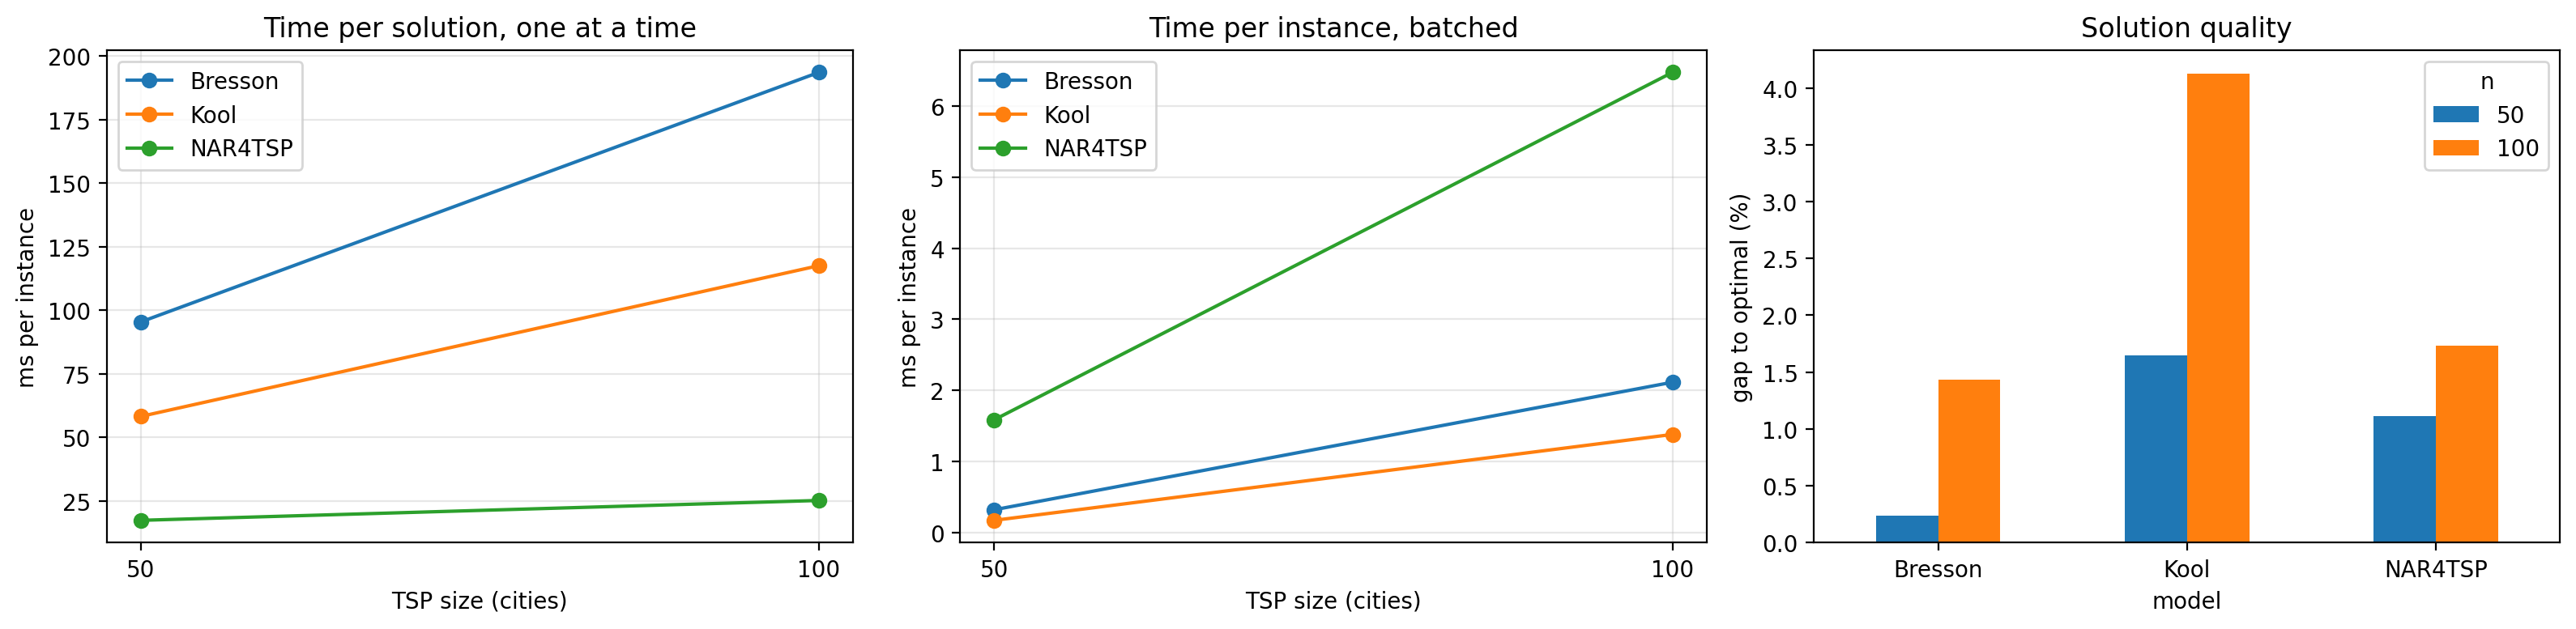

In [ ]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/TSP/results.csv")
df["mode_kind"] = df["mode"].str.replace(r"\d+", "", regex=True)      # bs / batch
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, kind, title in [(ax[0], "bs", "Time per solution, one at a time"),
                       (ax[1], "batch", "Time per instance, batched")]:
    for name, g in df[df.mode_kind == kind].groupby("model"):
        g = g.sort_values("n"); a.plot(g.n, g.ms_per_inst, marker="o", label=name)
    a.set_xticks([50, 100]); a.set_xlabel("TSP size (cities)"); a.set_ylabel("ms per instance")
    a.set_title(title); a.legend(); a.grid(alpha=0.3)
g = df[df.mode_kind == "batch"].pivot(index="model", columns="n", values="gap_pct")
g.plot.bar(ax=ax[2], rot=0); ax[2].set_ylabel("gap to optimal (%)"); ax[2].set_title("Solution quality")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Colab Notebooks/TSP/time_comparison.png", dpi=200); plt.show()

In [38]:
# # Cell A: inspect (no GPU, a few seconds). Run this first.

# import os, sys, inspect, subprocess
# BASE = "/content/drive/MyDrive/Colab Notebooks/TSP"

# print("=== NAR4TSP: lines mentioning beam ===")
# for f in ("val.py", "train.py"):
#     hits = [f"{f}:{i+1}: {l.strip()}" for i, l in enumerate(open(f"{BASE}/NAR4TSP/{f}").read().split("\n"))
#             if "beam" in l.lower()]
#     print("\n".join(hits) if hits else f"{f}: no 'beam' anywhere")

# print("\n=== Kool: how eval.py calls beam search ===")
# KOOL = f"{BASE}/attention-learn-to-route"
# print(subprocess.run(f'grep -n -B2 -A14 "beam_search(" "{KOOL}/eval.py"', shell=True,
#                      capture_output=True, text=True).stdout)

# print("=== Kool: TSP.beam_search and what utils/beam_search.py returns ===")
# sys.path.insert(0, KOOL); os.chdir(KOOL)
# from problems import TSP
# print(inspect.getsource(TSP.beam_search))
# print(subprocess.run(f'grep -n "^def \\|return" "{KOOL}/utils/beam_search.py"', shell=True,
#                      capture_output=True, text=True).stdout)

In [28]:
# cell B

import os, sys, json, ast, time, gc, statistics, torch, pandas as pd
from torch import nn

os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"
BASE = "/content/drive/MyDrive/Colab Notebooks/TSP"
CSV  = f"{BASE}/beam_results.csv"                 # separate from results.csv
dev  = torch.device("cuda"); print(torch.cuda.get_device_name(0))

N       = 100
WIDTHS  = list(range(100, 1001, 100))
# WIDTHS = [100, 200]           # as in the paper's Fig. 3(b)
M       = 100                                     # first 100 instances, batch size 1
NAR_K   = 20                                      # same value as the greedy benchmark; CHECK against val.py
NAR_BEAM = None                                   # fill in only if cell A found beam search in NAR4TSP, e.g.
                                                  # lambda score, edges, B: nar["beam_search"](score, edges, B)
BRE_CKPT = "checkpoint_21-03-01--17-09-47-n100-gpu0,1.pkl"
KOOL = f"{BASE}/attention-learn-to-route"; sys.path.insert(0, KOOL)

def sync(): torch.cuda.synchronize()
def tour_len(x, t):
    p = x.gather(1, t.unsqueeze(-1).expand(-1, -1, 2))
    return (p - p.roll(-1, dims=1)).norm(dim=2).sum(1)
def valid(t): return bool((t.sort(1).values == torch.arange(N, device=dev)).all())

# ---------- loaders: each returns (solve(xb, B) -> best tour (bsz, N), model) ----------
nar = {}
def load_nar():
    os.chdir(f"{BASE}/NAR4TSP"); sys.path.insert(0, f"{BASE}/NAR4TSP")
    tree = ast.parse(open("val.py").read())
    for node in tree.body:                         # only imports, functions, classes: no eval loop runs
        if isinstance(node, (ast.FunctionDef, ast.ClassDef, ast.Import, ast.ImportFrom)):
            try: exec(compile(ast.Module(body=[node], type_ignores=[]), "val.py", "exec"), nar)
            except Exception as e: print("NAR skipped:", type(node).__name__, getattr(node, "name", ""), "->", type(e).__name__)
    for fn in ("beam_search", "Generate_Two_Matrix", "PointGnnModel"):
        if fn not in nar: raise RuntimeError(f"{fn} not found in val.py")
    m = nn.DataParallel(nar["PointGnnModel"](128, 8, 6, 2))
    m.load_state_dict(torch.load(f"{BASE}/NAR4TSP/checkpoint/checkpoint-n{N}.pkl",
                                 map_location=dev, weights_only=False)["parameter"])
    core = m.to(dev).eval().module
    def solve(xb, B):
      with torch.no_grad():
          dis, mask = nar["Generate_Two_Matrix"](xb, NAR_K)
          score, edges = core(mask, dis, xb)
          nar["x"] = xb                                              # beam_search reads a global x
          tb = nar["beam_search"](score, edges, B).to(dev).long()    # (bsz, B, N)
      bsz = tb.shape[0]
      L = tour_len(xb.repeat_interleave(B, 0), tb.reshape(bsz * B, N)).view(bsz, B)
      return tb[torch.arange(bsz, device=dev), L.argmin(1)]
    return solve, core

def bresson_ns():
    nbk = json.load(open(f"{BASE}/TSP_Transformer/test_tsp_transformer_beamsearch_TSP{N}.ipynb"))
    code = "\n\n".join("".join(c["source"]) for c in nbk["cells"] if c["cell_type"] == "code")
    code = "\n".join(l for l in code.split("\n") if not l.lstrip().startswith(("%", "!")))
    prefix = code.split("model_baseline = TSP_net(")[0]
    ns = {"__name__": "bresson"}
    for node in ast.parse(prefix).body:
        seg = ast.get_source_segment(prefix, node) or ""
        if not isinstance(node, (ast.FunctionDef, ast.ClassDef)) and \
           any(k in seg for k in ("chdir", "drive.mount", "concorde", "google.colab")):
            continue
        try: exec(compile(ast.Module(body=[node], type_ignores=[]), "bresson", "exec"), ns)
        except Exception as e: print("skipped:", seg.split("\n")[0][:70], "->", type(e).__name__)
    return ns

def load_bre():
    ns = bresson_ns(); a = ns["args"]
    m = ns["TSP_net"](a.dim_input_nodes, a.dim_emb, a.dim_ff, a.nb_layers_encoder,
                      a.nb_layers_decoder, a.nb_heads, a.max_len_PE)
    ck = torch.load(f"{BASE}/TSP_Transformer/checkpoint/{BRE_CKPT}", map_location=dev, weights_only=False)
    m.load_state_dict({k.replace("module.", "", 1): v for k, v in ck["model_baseline"].items()})
    m = m.to(dev).eval()
    if torch.is_tensor(getattr(m, "PE", None)): m.PE = m.PE.to(dev)
    def solve(xb, B):
        with torch.no_grad():
            tb = m(xb, B, False, True)[1]                         # (bsz, B, N): all B beams
        bsz = tb.shape[0]
        L = tour_len(xb.repeat_interleave(B, 0), tb.reshape(bsz * B, N)).view(bsz, B)
        return tb[torch.arange(bsz, device=dev), L.argmin(1)]     # shortest of the B tours
    return solve, m

def load_kool():
    os.chdir(KOOL)
    from utils import load_model
    m, _ = load_model(f"{KOOL}/pretrained/tsp_{N}")
    m = m.to(dev).eval(); m.set_decode_type("greedy")
    def solve(xb, B):
      if len(xb) != 1:
          raise RuntimeError("Kool loader assumes batch size 1")
      with torch.no_grad():
          out = m.beam_search(xb, beam_size=B) # (cum_log_p, sequences, costs, ids, batch_size)
      seq = out[1]
      if seq is None:
          raise RuntimeError("Kool beam search returned no solution")
      if not torch.is_tensor(seq):
          seq = torch.stack([torch.as_tensor(s) for s in seq])
      seq = seq.to(dev).long()
      if seq.dim() != 2 or seq.shape[1] != N:
          raise RuntimeError(f"unexpected Kool output shape {tuple(seq.shape)}")
      L = tour_len(xb.expand(seq.shape[0], -1, -1), seq) # our own length for each beam's tour
      return seq[L.argmin()].unsqueeze(0) # shortest tour, shape (1, N)
    return solve, m

LOADERS = {"NAR4TSP": load_nar, "Bresson": load_bre, "Kool": load_kool}

# ---------- one beam width: time per solution at batch size 1 ----------
def run_width(solve, B, X, OPT):
    solve(X[:1], B)                                               # warm-up, not timed
    torch.cuda.reset_peak_memory_stats()
    ts, tours = [], []
    for i in range(M):
        sync(); t0 = time.time(); t = solve(X[i:i+1], B); sync()
        ts.append(time.time() - t0); tours.append(t)
    T = torch.cat(tours)
    return {"mean_s": statistics.mean(ts), "median_s": statistics.median(ts),
            "gap_pct": (tour_len(X, T).mean().item() / OPT - 1) * 100, "valid": valid(T),
            "peak_gb": torch.cuda.max_memory_allocated() / 1e9}

X   = torch.load(f"{BASE}/TSP_Transformer/data/10k_TSP{N}.pt", map_location=dev, weights_only=False)[:M]
OPT = torch.load(f"{BASE}/TSP_Transformer/data/10k_TSP{N}_len.pt", map_location="cpu",
                 weights_only=False)[:M].float().mean().item()

rows = pd.read_csv(CSV).to_dict("records") if os.path.exists(CSV) else []   # resume after a disconnect
done = {(r["model"], r["B"]) for r in rows}

for name, loader in LOADERS.items():
    todo = [B for B in WIDTHS if (name, B) not in done]
    if not todo: continue
    try: solve, model = loader()
    except Exception as e: print(f"{name}: skipped ({type(e).__name__}: {str(e)[:150]})"); continue
    for B in todo:
        try: r = run_width(solve, B, X, OPT)
        except torch.cuda.OutOfMemoryError: print(f"{name} B={B}: out of memory, skipping larger widths"); break
        except Exception as e: print(f"{name} B={B} failed: {type(e).__name__}: {str(e)[:200]}"); break
        rows.append({"model": name, "n": N, "B": B, "n_inst": M, **r})
        pd.DataFrame(rows).to_csv(CSV, index=False)                         # saved after every width
        print(f"{name:8s} B={B:4d}: {r['mean_s']*1000:7.1f} ms/solution, gap {r['gap_pct']:.2f}%, "
              f"valid={r['valid']}, peak {r['peak_gb']:.2f} GB")
    del solve, model; gc.collect(); torch.cuda.empty_cache()

print(pd.DataFrame(rows).round(4).to_string(index=False))

Tesla T4
NAR4TSP  B= 300:    66.4 ms/solution, gap 1.13%, valid=True, peak 0.08 GB
NAR4TSP  B= 400:    81.4 ms/solution, gap 1.10%, valid=True, peak 0.08 GB
NAR4TSP  B= 500:    68.4 ms/solution, gap 1.08%, valid=True, peak 0.08 GB
NAR4TSP  B= 600:    79.8 ms/solution, gap 1.06%, valid=True, peak 0.08 GB
NAR4TSP  B= 700:    69.3 ms/solution, gap 1.05%, valid=True, peak 0.08 GB
NAR4TSP  B= 800:    78.5 ms/solution, gap 1.04%, valid=True, peak 0.08 GB
NAR4TSP  B= 900:    86.8 ms/solution, gap 1.03%, valid=True, peak 0.08 GB
NAR4TSP  B=1000:    73.1 ms/solution, gap 1.01%, valid=True, peak 0.08 GB
GPU name: Tesla T4, gpu_id: 0,1
cuda
{'nb_nodes': 100, 'bsz': 512, 'dim_emb': 128, 'dim_ff': 512, 'dim_input_nodes': 2, 'nb_layers_encoder': 6, 'nb_layers_decoder': 2, 'nb_heads': 8, 'nb_epochs': 10000, 'nb_batch_per_epoch': 2500, 'nb_batch_eval': 20, 'gpu_id': '0,1', 'lr': 0.0001, 'tol': 0.001, 'batchnorm': True, 'max_len_PE': 1000}
Bresson  B= 300:   386.0 ms/solution, gap 0.56%, valid=True, pe

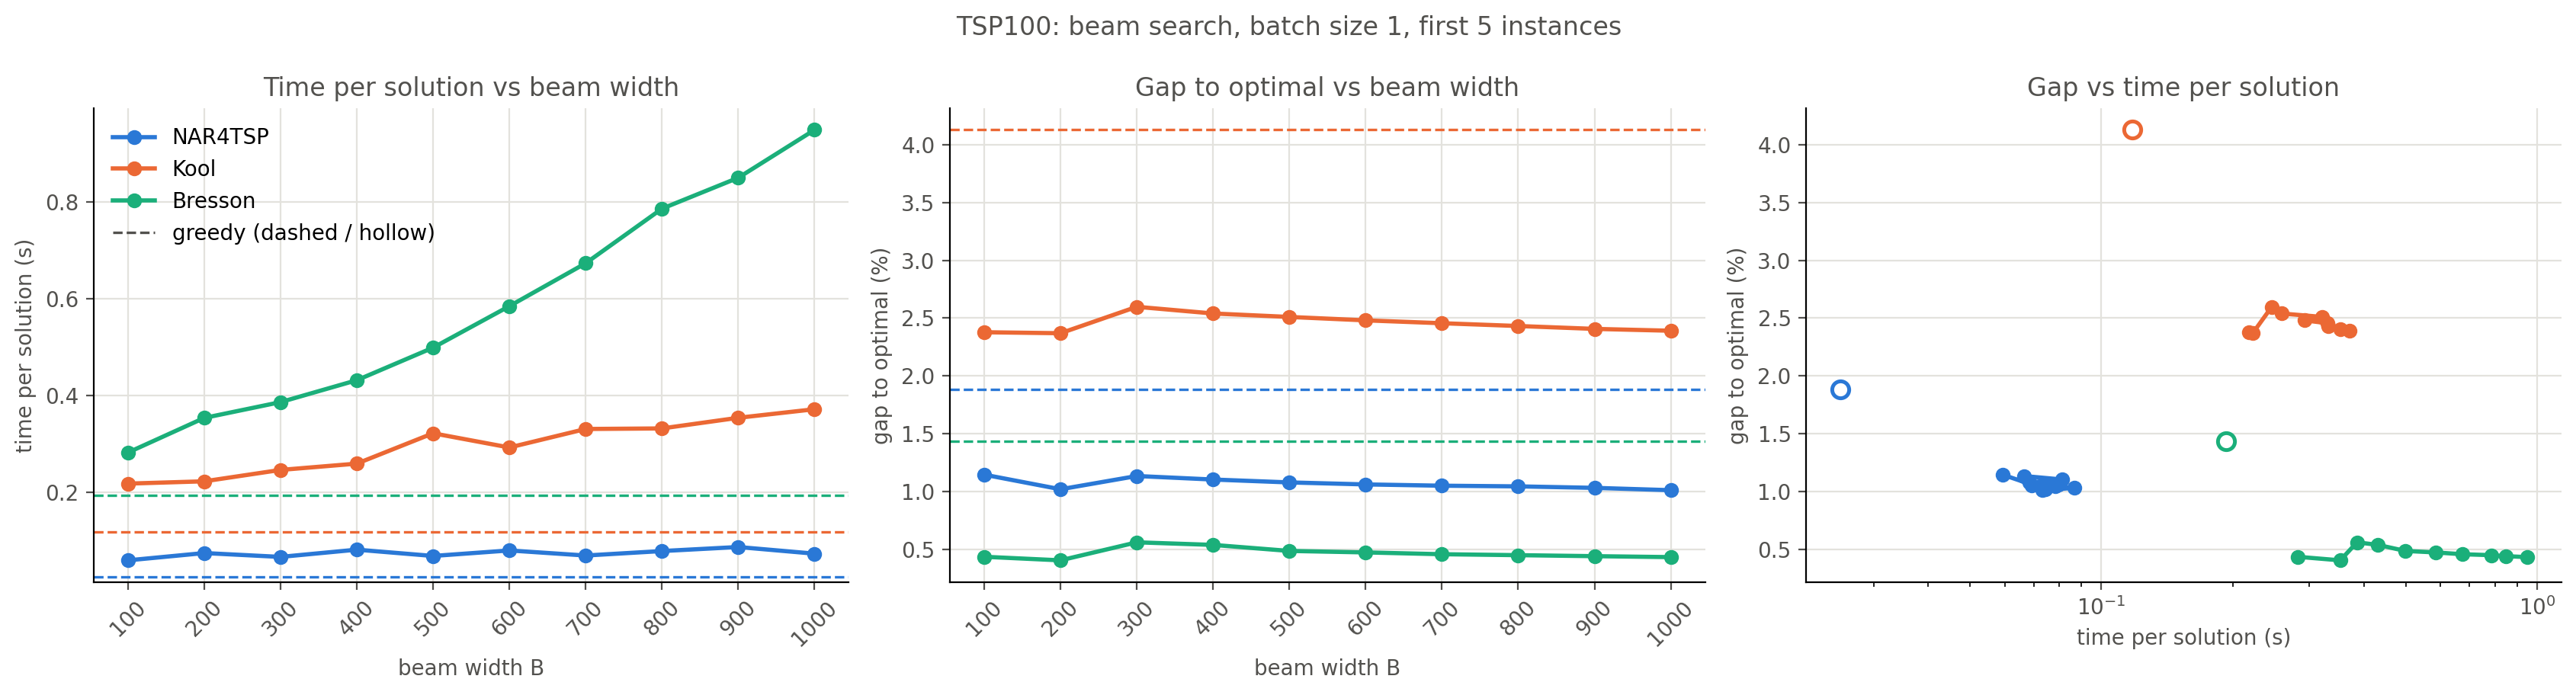

In [30]:
# cell C

import pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

BASE = "/content/drive/MyDrive/Colab Notebooks/TSP"
bm = pd.read_csv(f"{BASE}/beam_results.csv")
gr = pd.read_csv(f"{BASE}/results.csv")
gr = gr[(gr.n == 100) & (gr["mode"] == "bs1")].set_index("model")      # greedy, batch size 1, from the first benchmark

COL = {"NAR4TSP": "#2a78d6", "Kool": "#eb6834", "Bresson": "#1baf7a"}   # fixed colour per model
INK, GRID = "#52514e", "#e3e2dd"
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

for name, g in bm.groupby("model"):
    g = g.sort_values("B")
    ax[0].plot(g.B, g.mean_s, marker="o", ms=6, lw=2, color=COL[name], label=name)
    ax[1].plot(g.B, g.gap_pct, marker="o", ms=6, lw=2, color=COL[name], label=name)
    ax[2].plot(g.mean_s, g.gap_pct, marker="o", ms=6, lw=2, color=COL[name], label=name)

for name, r in gr.iterrows():                                           # greedy reference: dashed line / hollow marker
    ax[0].axhline(r.ms_per_inst / 1000, color=COL[name], ls="--", lw=1.2)
    ax[1].axhline(r.gap_pct, color=COL[name], ls="--", lw=1.2)
    ax[2].plot(r.ms_per_inst / 1000, r.gap_pct, marker="o", ms=8, mfc="none", mew=1.8, color=COL[name], ls="")

titles = ["Time per solution vs beam width", "Gap to optimal vs beam width", "Gap vs time per solution"]
xl = ["beam width B", "beam width B", "time per solution (s)"]
yl = ["time per solution (s)", "gap to optimal (%)", "gap to optimal (%)"]
for a, t, x, y in zip(ax, titles, xl, yl):
    a.set_title(t, color=INK); a.set_xlabel(x, color=INK); a.set_ylabel(y, color=INK)
    a.grid(color=GRID, lw=0.8); a.set_axisbelow(True)
    for s in ("top", "right"): a.spines[s].set_visible(False)
    a.tick_params(colors=INK)
for a in ax[:2]: a.set_xticks(range(100, 1001, 100)); a.tick_params(axis="x", labelrotation=45)
ax[2].set_xscale("log")

handles = [Line2D([], [], color=c, marker="o", lw=2, label=n) for n, c in COL.items() if n in set(bm.model) | set(gr.index)]
handles += [Line2D([], [], color=INK, ls="--", lw=1.2, label="greedy (dashed / hollow)")]
ax[0].legend(handles=handles, frameon=False)
fig.suptitle(f"TSP{int(bm.n.iloc[0])}: beam search, batch size 1, first {int(bm.n_inst.iloc[0])} instances", color=INK)
plt.tight_layout()
plt.savefig(f"{BASE}/beam_comparison.png", dpi=200); plt.show()

In [31]:
solve, m = load_kool()
xs = X[:5]
optm = torch.load(f"{BASE}/TSP_Transformer/data/10k_TSP{N}_len.pt", map_location="cpu", weights_only=False)[:5].float().mean().item()

with torch.no_grad():
    for B in (10, 100, 200):
        out = m.beam_search(xs[:1], beam_size=B)
        s = out[1]
        print(f"B={B}: type {type(s).__name__}, shape {tuple(s.shape) if torch.is_tensor(s) else len(s)}, out[2]={out[2]}")
    m.set_decode_type("greedy")
    cost, _ = m(xs)                                    # Kool's own greedy rollout
    print("Kool greedy gap on the same 5 instances: %.2f%%" % ((cost.mean().item() / optm - 1) * 100))

  [*] Loading model from /content/drive/MyDrive/Colab Notebooks/TSP/attention-learn-to-route/pretrained/tsp_100/epoch-99.pt
B=10: type Tensor, shape (10, 100), out[2]=tensor([7.9612, 7.9558, 8.0582, 7.9526, 8.0528, 7.9472, 8.1616, 8.1598, 8.0018,
        8.0431], device='cuda:0')
B=100: type Tensor, shape (100, 100), out[2]=tensor([7.9612, 7.9558, 7.9619, 8.0582, 7.9526, 7.9565, 8.0528, 7.9472, 8.1616,
        8.1598, 8.0018, 8.0589, 8.0431, 7.9533, 7.9720, 8.1562, 8.1544, 8.0496,
        7.9964, 7.9651, 8.0536, 8.0377, 7.9479, 8.1623, 7.9666, 8.1783, 8.1605,
        8.1765, 7.9679, 8.0931, 8.1674, 8.0025, 8.1507, 8.1655, 8.0439, 7.9735,
        8.0442, 7.9727, 7.9597, 8.1530, 8.1512, 8.0988, 8.1569, 8.1729, 7.9932,
        8.1551, 7.9928, 8.0959, 8.0690, 8.1319, 8.1711, 8.1301, 7.9625, 8.0503,
        8.0877, 8.1620, 8.0345, 7.9971, 8.1453, 7.9634, 8.1601, 7.9658, 7.9403,
        8.1414, 8.1396, 8.0385, 7.9681, 7.9673, 8.1791, 8.1476, 8.1772, 8.1458,
        7.9988, 7.9686, 8.0938, 8.

In [34]:
# Cell D for baseline

import os, time, statistics, numpy as np, pandas as pd, torch
from numba import njit

@njit(cache=True)
def tour_length(D, t):
    s = 0.0
    for i in range(len(t)):
        s += D[t[i], t[(i + 1) % len(t)]]
    return s

@njit(cache=True)
def nearest_neighbor(D):
    n = D.shape[0]
    vis = np.zeros(n, np.bool_); t = np.empty(n, np.int64)
    t[0] = 0; vis[0] = True
    for k in range(1, n):
        c = t[k - 1]; best = -1; bd = 1e18
        for j in range(n):
            if not vis[j] and D[c, j] < bd: bd = D[c, j]; best = j
        t[k] = best; vis[best] = True
    return t

@njit(cache=True)
def insertion(D, farthest):
    n = D.shape[0]
    in_t = np.zeros(n, np.bool_)
    tour = np.empty(n, np.int64); m = 2
    j0 = -1; bd = -1e18 if farthest else 1e18          # start: city 0 + its farthest (or nearest) city
    for j in range(1, n):
        if (farthest and D[0, j] > bd) or ((not farthest) and D[0, j] < bd): bd = D[0, j]; j0 = j
    tour[0] = 0; tour[1] = j0; in_t[0] = True; in_t[j0] = True
    mind = np.empty(n)                                  # distance from each city to the current tour
    for j in range(n): mind[j] = min(D[j, 0], D[j, j0])
    while m < n:
        c = -1; bd = -1e18 if farthest else 1e18        # pick the city to insert
        for j in range(n):
            if in_t[j]: continue
            if (farthest and mind[j] > bd) or ((not farthest) and mind[j] < bd): bd = mind[j]; c = j
        bi = 0; bc = 1e18                               # cheapest place to insert it
        for i in range(m):
            a = tour[i]; b = tour[(i + 1) % m]
            cost = D[a, c] + D[c, b] - D[a, b]
            if cost < bc: bc = cost; bi = i
        for k in range(m, bi + 1, -1): tour[k] = tour[k - 1]
        tour[bi + 1] = c; m += 1; in_t[c] = True
        for j in range(n):
            if not in_t[j] and D[j, c] < mind[j]: mind[j] = D[j, c]
    return tour

@njit(cache=True)
def aco(D, n_ants, n_iter, alpha, beta, rho, seed):
    np.random.seed(seed)
    n = D.shape[0]
    eta = np.empty((n, n))
    for i in range(n):
        for j in range(n): eta[i, j] = 1.0 / (D[i, j] + 1e-10) if i != j else 0.0
    L0 = tour_length(D, nearest_neighbor(D))
    tau = np.full((n, n), 1.0 / (n * L0))
    best = np.empty(n, np.int64); bestL = 1e18
    tours = np.empty((n_ants, n), np.int64); Ls = np.empty(n_ants)
    w = np.empty(n); vis = np.zeros(n, np.bool_)
    for it in range(n_iter):
        for a in range(n_ants):
            vis[:] = False
            c = np.random.randint(0, n); tours[a, 0] = c; vis[c] = True
            for k in range(1, n):
                tot = 0.0
                for j in range(n):
                    if vis[j]: w[j] = 0.0
                    else: w[j] = (tau[c, j] ** alpha) * (eta[c, j] ** beta)
                    tot += w[j]
                r = np.random.random() * tot; acc = 0.0; nxt = -1
                for j in range(n):
                    if w[j] > 0.0:
                        acc += w[j]; nxt = j
                        if acc >= r: break
                tours[a, k] = nxt; vis[nxt] = True; c = nxt
            Ls[a] = tour_length(D, tours[a])
            if Ls[a] < bestL: bestL = Ls[a]; best[:] = tours[a]
        tau *= (1.0 - rho)
        for a in range(n_ants):                         # every ant deposits 1/L
            d = 1.0 / Ls[a]
            for k in range(n):
                i = tours[a, k]; j = tours[a, (k + 1) % n]
                tau[i, j] += d; tau[j, i] += d
        d = 2.0 / bestL                                 # elitist: best-so-far tour deposits extra
        for k in range(n):
            i = best[k]; j = best[(k + 1) % n]
            tau[i, j] += d; tau[j, i] += d
    return best

# ---------------- run ----------------
BASE = "/content/drive/MyDrive/Colab Notebooks/TSP"
CSV  = f"{BASE}/classic_results.csv"                    # separate file; resumes if it exists
N, M = 100, 100                                         # M = 3 for a smoke test (use a temp CSV)
ACO_ANTS, ACO_ITERS = 20, 1000                          # from the paper's Table II; alpha, beta, rho are my choice

X   = torch.load(f"{BASE}/TSP_Transformer/data/10k_TSP{N}.pt", map_location="cpu", weights_only=False)[:M].double().numpy()
OPT = torch.load(f"{BASE}/TSP_Transformer/data/10k_TSP{N}_len.pt", map_location="cpu", weights_only=False)[:M].double().numpy()
Ds  = [np.sqrt(((x[:, None] - x[None]) ** 2).sum(-1)) for x in X]

ALGOS = {
    "Nearest neighbor":   lambda D, i: nearest_neighbor(D),
    "Nearest insertion":  lambda D, i: insertion(D, False),
    "Farthest insertion": lambda D, i: insertion(D, True),
    # "ACO":                lambda D, i: aco(D, ACO_ANTS, ACO_ITERS, 1.0, 3.0, 0.1, i),
}
rows = pd.read_csv(CSV).to_dict("records") if os.path.exists(CSV) else []
done = {r["model"] for r in rows}
for name, f in ALGOS.items():
    if name in done: continue
    f(Ds[0], 0)                                         # JIT compile, not timed
    ts, Ls, ok = [], [], True
    for i in range(M):
        t0 = time.perf_counter(); t = f(Ds[i], i); ts.append(time.perf_counter() - t0)
        ok &= sorted(t.tolist()) == list(range(N)); Ls.append(tour_length(Ds[i], t))
    gap = (np.mean(Ls) / OPT.mean() - 1) * 100
    rows.append({"model": name, "n": N, "n_inst": M, "ms_per_inst": 1000 * statistics.mean(ts),
                 "median_ms": 1000 * statistics.median(ts), "gap_pct": gap, "valid": ok, "device": "cpu"})
    pd.DataFrame(rows).to_csv(CSV, index=False)
    print(f"{name:19s}: {rows[-1]['ms_per_inst']:9.2f} ms/inst, gap {gap:6.2f}%, valid={ok}")

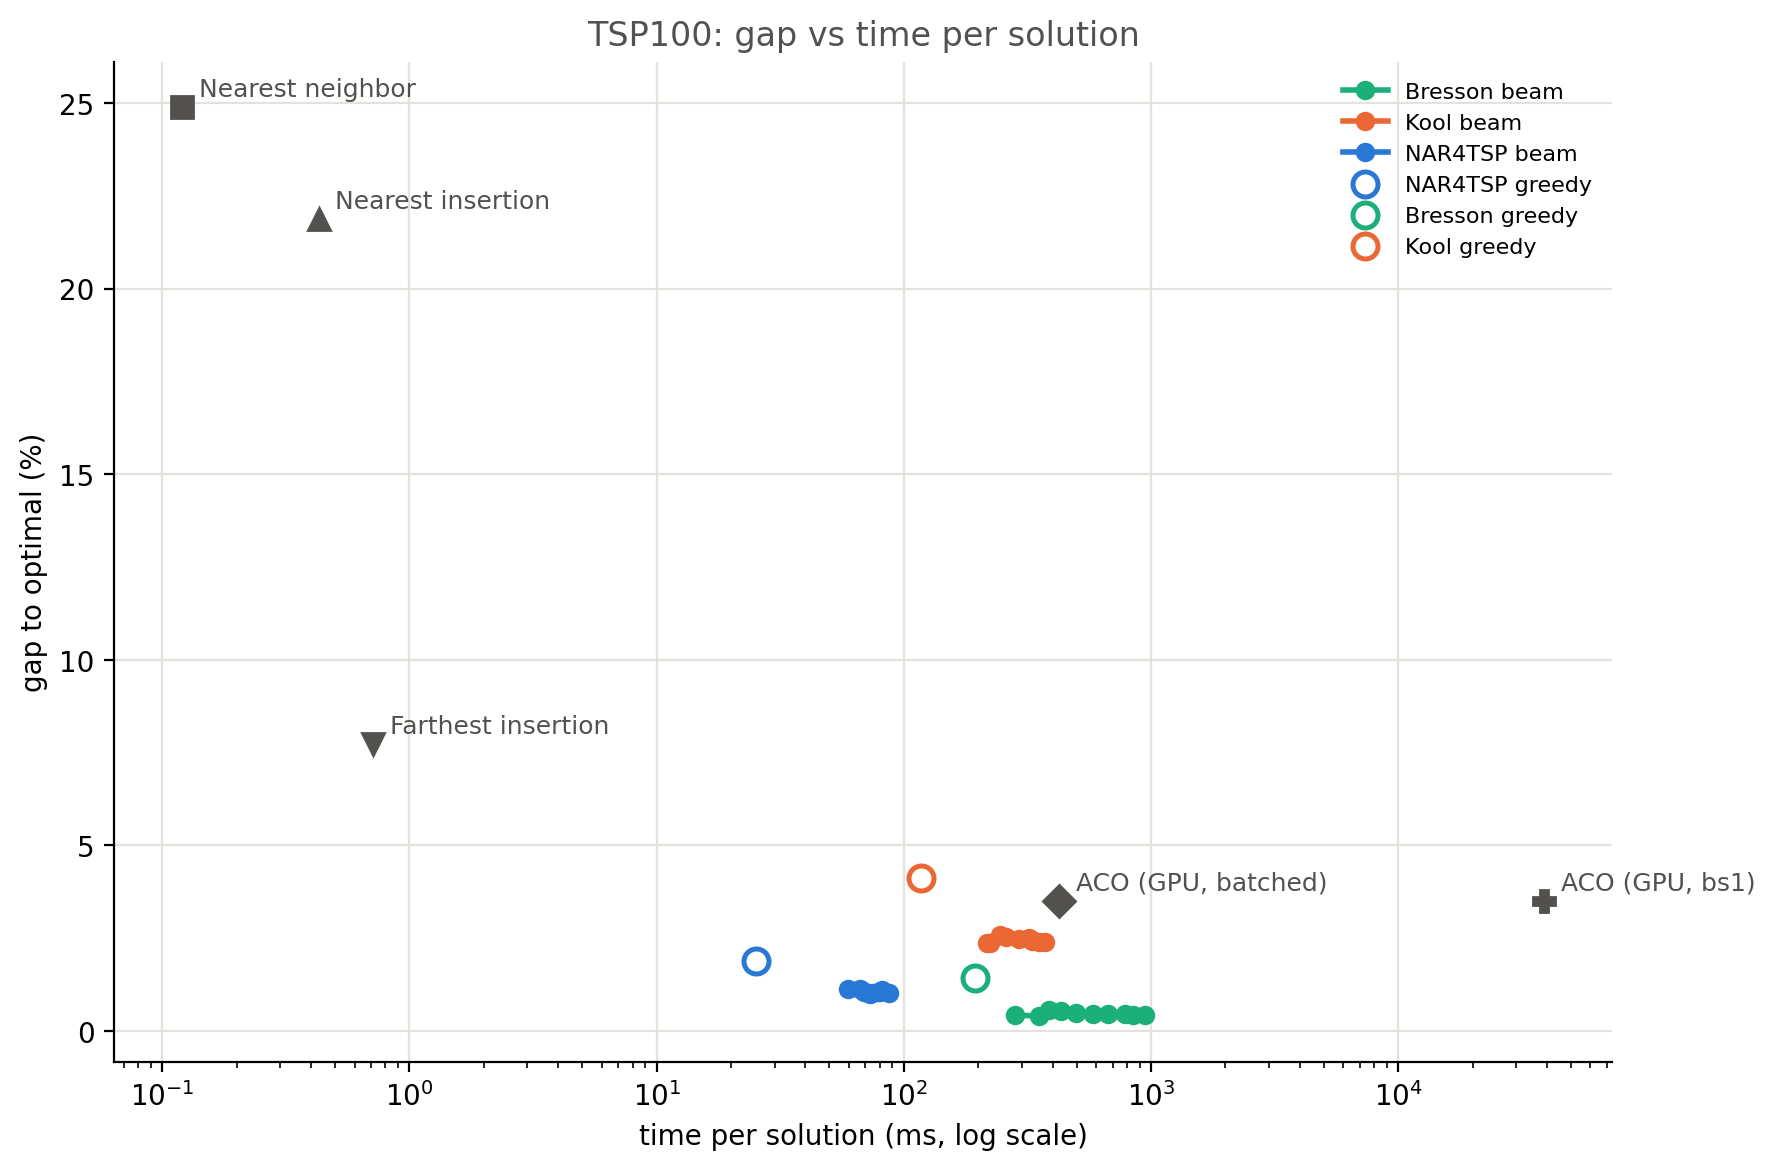

In [37]:
import itertools, pandas as pd, matplotlib.pyplot as plt
BASE = "/content/drive/MyDrive/Colab Notebooks/TSP"
bm = pd.read_csv(f"{BASE}/beam_results.csv")
gr = pd.read_csv(f"{BASE}/results.csv"); gr = gr[(gr.n == 100) & (gr["mode"] == "bs1")]
cl = pd.read_csv(f"{BASE}/classic_results.csv")
COL = {"NAR4TSP": "#2a78d6", "Kool": "#eb6834", "Bresson": "#1baf7a"}
INK, GRID = "#52514e", "#e3e2dd"

fig, ax = plt.subplots(figsize=(9, 6))
for name, g in bm.groupby("model"):
    g = g.sort_values("B"); ax.plot(g.mean_s * 1000, g.gap_pct, "o-", color=COL[name], lw=2, label=f"{name} beam")
for _, r in gr.iterrows():
    ax.plot(r.ms_per_inst, r.gap_pct, "o", mfc="none", mew=1.8, ms=9, color=COL[r.model], label=f"{r.model} greedy")
for (_, r), mk in zip(cl.iterrows(), itertools.cycle("s^vDP*")):
    ax.plot(r.ms_per_inst, r.gap_pct, mk, color=INK, ms=8)
    ax.annotate(r.model, (r.ms_per_inst, r.gap_pct), textcoords="offset points", xytext=(6, 4), color=INK, fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("time per solution (ms, log scale)"); ax.set_ylabel("gap to optimal (%)")
ax.set_title("TSP100: gap vs time per solution", color=INK)
ax.grid(color=GRID); ax.set_axisbelow(True)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(f"{BASE}/all_comparison.png", dpi=200); plt.show()

In [36]:
# cell F ACO on gpu

import os, time, statistics, torch, pandas as pd

BASE = "/content/drive/MyDrive/Colab Notebooks/TSP"
CSV  = f"{BASE}/classic_results.csv"             # same file as cell D; rows are appended
dev  = torch.device("cuda")
N, M = 100, 100                                  # M = 3 for a smoke test (use a temp CSV)
ANTS, ITERS = 20, 1000
ALPHA, BETA, RHO = 1.0, 3.0, 0.1                 # same as the CPU version
BS1_INST = 3                                     # instances used to time batch size 1 (each takes seconds)

def nn_len(D):                                   # nearest-neighbour tour length from city 0 (for tau0), batched
    B, n, _ = D.shape; ar = torch.arange(B, device=D.device)
    vis = torch.zeros(B, n, dtype=torch.bool, device=D.device)
    cur = torch.zeros(B, dtype=torch.long, device=D.device); vis[ar, cur] = True
    L = torch.zeros(B, device=D.device)
    for _ in range(n - 1):
        d = D[ar, cur].masked_fill(vis, float("inf"))
        nxt = d.argmin(1); L += d[ar, nxt]; vis[ar, nxt] = True; cur = nxt
    return L + D[ar, cur, 0]

def aco_gpu(X, n_ants=ANTS, n_iter=ITERS, alpha=ALPHA, beta=BETA, rho=RHO, seed=0):
    """X: (B, n, 2) on cuda. Returns best tours (B, n) and their lengths (B,)."""
    B, n, _ = X.shape; dev = X.device
    g = torch.Generator(device=dev); g.manual_seed(seed)
    D = torch.cdist(X.float(), X.float())                              # (B, n, n)
    eta = 1.0 / (D + 1e-10); eta.diagonal(dim1=1, dim2=2).zero_()
    eta_b = eta ** beta
    tau = (1.0 / (n * nn_len(D))).view(B, 1, 1).expand(B, n, n).clone()
    arB = torch.arange(B, device=dev); b1 = arB.view(B, 1); b3 = arB.view(B, 1, 1)
    arA = torch.arange(n_ants, device=dev).view(1, n_ants)
    best_len = torch.full((B,), float("inf"), device=dev)
    best_tour = torch.zeros(B, n, dtype=torch.long, device=dev)
    for it in range(n_iter):
        W = (tau ** alpha if alpha != 1.0 else tau) * eta_b            # desirability of each edge
        cur = torch.randint(0, n, (B, n_ants), device=dev, generator=g)
        tours = torch.empty(B, n_ants, n, dtype=torch.long, device=dev); tours[:, :, 0] = cur
        vis = torch.zeros(B, n_ants, n, dtype=torch.bool, device=dev); vis[b1, arA, cur] = True
        for k in range(1, n):                                          # all ants of all instances step together
            w = W[b1, cur].masked_fill(vis, 0.0)                       # (B, A, n)
            nxt = torch.multinomial(w.view(B * n_ants, n), 1, generator=g).view(B, n_ants)
            tours[:, :, k] = nxt; vis[b1, arA, nxt] = True; cur = nxt
        L = D[b3, tours, tours.roll(-1, 2)].sum(-1)                    # (B, A)
        mL, mi = L.min(1); imp = mL < best_len
        best_len = torch.where(imp, mL, best_len)
        best_tour = torch.where(imp.unsqueeze(1), tours[arB, mi], best_tour)
        # pheromone: evaporate, every ant deposits 1/L, best-so-far deposits 2/L (elitist)
        delta = torch.zeros(B * n * n, device=dev)
        idx = (b3 * n * n + tours * n + tours.roll(-1, 2)).reshape(-1)
        delta.index_add_(0, idx, (1.0 / L).unsqueeze(-1).expand(B, n_ants, n).reshape(-1))
        idx = (b1 * n * n + best_tour * n + best_tour.roll(-1, 1)).reshape(-1)
        delta.index_add_(0, idx, (2.0 / best_len).unsqueeze(-1).expand(B, n).reshape(-1))
        delta = delta.view(B, n, n)
        tau = ((1 - rho) * tau + delta + delta.transpose(1, 2)).clamp_(min=1e-12)   # floor avoids float32 underflow
    return best_tour, best_len

# ---------------- data ----------------
X   = torch.load(f"{BASE}/TSP_Transformer/data/10k_TSP{N}.pt", map_location=dev, weights_only=False)[:M].float()
OPT = torch.load(f"{BASE}/TSP_Transformer/data/10k_TSP{N}_len.pt", map_location="cpu", weights_only=False)[:M].float().mean().item()

def tour_len(x, t):
    p = x.gather(1, t.unsqueeze(-1).expand(-1, -1, 2))
    return (p - p.roll(-1, dims=1)).norm(dim=2).sum(1)
def valid(t): return bool((t.sort(1).values == torch.arange(N, device=dev)).all())

rows = pd.read_csv(CSV).to_dict("records") if os.path.exists(CSV) else []
done = {r["model"] for r in rows}
aco_gpu(X[:1], n_iter=2)                                              # warm-up, not timed
torch.cuda.synchronize()

# 1) all M instances at once: quality + batched time (total / M)
if "ACO (GPU, batched)" not in done:
    t0 = time.time(); T, _ = aco_gpu(X); torch.cuda.synchronize(); tot = time.time() - t0
    gap = (tour_len(X, T).mean().item() / OPT - 1) * 100; ok = valid(T)
    rows.append({"model": "ACO (GPU, batched)", "n": N, "n_inst": M, "ms_per_inst": 1000 * tot / M,
                 "median_ms": float("nan"), "gap_pct": gap, "valid": ok, "device": "gpu"})
    pd.DataFrame(rows).to_csv(CSV, index=False)
    print(f"ACO (GPU, batched): {1000*tot/M:8.1f} ms/inst, gap {gap:.2f}%, valid={ok}")

# 2) batch size 1: time on the first BS1_INST instances; gap is copied from the batched run (same algorithm)
if "ACO (GPU, bs1)" not in done:
    ts = []
    for i in range(BS1_INST):
        torch.cuda.synchronize(); t0 = time.time(); aco_gpu(X[i:i+1], seed=i); torch.cuda.synchronize()
        ts.append(time.time() - t0); print(f"  bs1 instance {i}: {ts[-1]:.1f} s")
    g = [r for r in rows if r["model"] == "ACO (GPU, batched)"][0]
    rows.append({"model": "ACO (GPU, bs1)", "n": N, "n_inst": BS1_INST, "ms_per_inst": 1000 * statistics.mean(ts),
                 "median_ms": 1000 * statistics.median(ts), "gap_pct": g["gap_pct"], "valid": g["valid"], "device": "gpu"})
    pd.DataFrame(rows).to_csv(CSV, index=False)
    print(f"ACO (GPU, bs1)    : {1000*statistics.mean(ts):8.1f} ms/inst (gap taken from the batched run)")

ACO (GPU, batched):    425.3 ms/inst, gap 3.52%, valid=True
  bs1 instance 0: 39.8 s
  bs1 instance 1: 38.6 s
  bs1 instance 2: 38.6 s
ACO (GPU, bs1)    :  39011.5 ms/inst (gap taken from the batched run)
